Features: testing new festures
- Mutual information
- 8 new group features: none helped
- K-means clustering and distances: slightly worse

In [ ]:
import pandas as pd
import numpy as np
import lightgbm as lgb
from sklearn.model_selection import KFold
from sklearn.metrics import root_mean_squared_log_error

train = pd.read_csv("train.csv")
y = np.log1p(train["hours_spent"])
X_raw = train.drop(columns=["hours_spent", "log_hours", "hours_bucket", "project_id"])

In [2]:
ORDER_MAPS ={
    "author_prior_projects": {"0":0, "1-2":1, "3-5":2, "6+":3},
    "author_account_age_years": {"<1":0, "1-2":1, "3-5":2, "6+":3},
}

def encode_ordered(df):
    df = df.copy()
    for col, mapping in ORDER_MAPS.items():
        df[col] = df[col].astype(str).map(mapping)
    return df

In [3]:
def encode_yes_no(df):
    df = df.copy()
    for col in df.select_dtypes(include="object").columns:
        values = set(df[col].dropna().astype(str).unique())
        if values <= {"True", "False"}:
            df[col] = df[col].astype(str).map({"True": 1.0, "False": 0.0})
    return df

In [4]:
def encode_categories(df):
    df = df.copy()
    for col in df.select_dtypes(include="object").columns:
        df[col] = df[col].astype("category")
    return df

In [5]:
def prepare_base(df):
    df = encode_ordered(df)
    df = encode_yes_no(df)
    df = encode_categories(df)
    return df

In [6]:
def add_features(df):
    df = df.copy()
    df["biggest_commit_share"] = df["max_lines_in_one_commit"] / df["lines_added_total"].replace(0, np.nan)
    df["lines_per_active_day"] = df["lines_of_code"] / df["active_commit_days"].replace(0, np.nan)
    df["commits_per_active_day"] = df["num_commits"] / df["active_commit_days"].replace(0, np.nan)
    df["active_day_ratio"] = df["active_commit_days"] / (df["project_span_days"] + 1)
    return df

In [7]:
X_base = prepare_base(X_raw)
X_ours = add_features(X_base)

kf = KFold(n_splits=5, shuffle=True, random_state=42)
print(X_base.shape, X_ours.shape)

(4500, 69) (4500, 73)


C:\Users\Fujitsu\AppData\Local\Temp\ipykernel_12780\1303781909.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df.select_dtypes(include="object").columns:
C:\Users\Fujitsu\AppData\Local\Temp\ipykernel_12780\3138021966.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guid

In [8]:
BEST_LGB = {
    "n_estimators": 865, "learning_rate": 0.012964449902814406, "num_leaves": 35,
    "min_child_samples": 11, "subsample": 0.870297694890708,
    "colsample_bytree": 0.5828255385942684, "reg_lambda": 0.002402089003977252,
}

def test_features(X_data):
    oof = np.zeros(len(X_data))
    for tr, te in kf.split(X_data):
        m = lgb.LGBMRegressor(**BEST_LGB, subsample_freq=1, random_state=42, verbose=-1)
        m.fit(X_data.iloc[tr],y.iloc[tr])
        oof[te] = m.predict(X_data.iloc[te])
    pred = np.expm1(oof).clip(0, 140.7)
    return root_mean_squared_log_error(train["hours_spent"], pred)

print("Without our clues: ", round(test_features(X_base), 4))
print("With our 4 clues: ", round(test_features(X_ours), 4))

Without our clues:  0.6623
With our 4 clues:  0.6554


active_commit_days          0.268972
lines_of_code               0.247346
lines_added_total           0.234563
num_commits                 0.195468
pct_commits_weekend         0.192139
num_source_files            0.182004
biggest_commit_share        0.179015
project_span_days           0.166576
lines_deleted_total         0.159445
primary_language            0.152520
pct_generic_commit_msgs     0.150742
readme_word_count           0.146257
pct_code_in_first_commit    0.143463
max_lines_in_one_commit     0.134429
num_directories             0.130986
hosting_type                0.127441
lines_per_active_day        0.126190
pct_commits_late_night      0.121810
active_day_ratio            0.115946
max_dir_depth               0.114526
dtype: float64

Clues with almost no information: 
has_tests                  0.009251
is_multiplayer             0.007992
mentions_ai_api            0.006837
url_is_live                0.006836
has_docs_folder            0.004820
has_dockerfile             0.

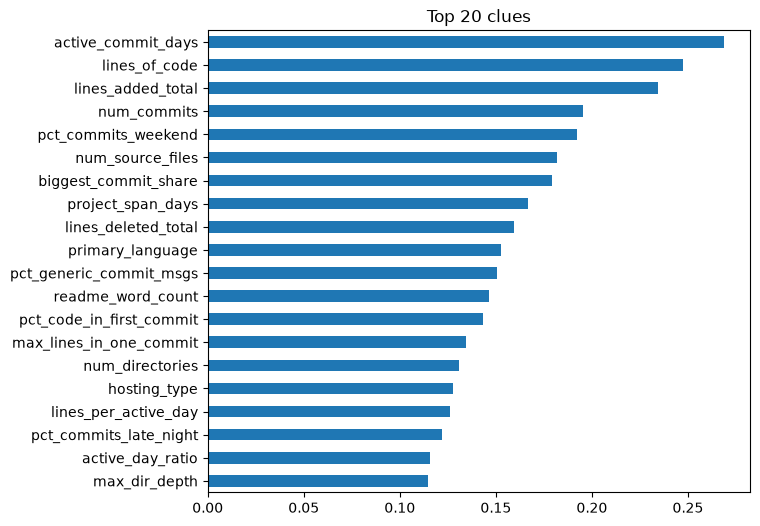

In [9]:
from sklearn.feature_selection import mutual_info_regression
import matplotlib.pyplot as plt

X_mi = X_ours.copy()
for c in X_mi.select_dtypes(include="category").columns:
    X_mi[c] = X_mi[c].cat.codes
X_mi = X_mi.fillna(-1)

discrete = (X_mi.nunique() <= 10).values

mi = mutual_info_regression(X_mi, y, discrete_features=discrete, random_state=0)
mi = pd.Series(mi, index=X_mi.columns).sort_values(ascending=False)

print(mi.head(20))
print()
print("Clues with almost no information: ")
print(mi[mi < 0.01])

mi.head(20).sort_values().plot.barh(figsize=(7,6), title="Top 20 clues")
plt.show()

In [10]:
def add_features_v2(df):
    df = df.copy()

    df["lines_added_per_commit"] = df["lines_added_total"] / df["num_commits"].replace(0, np.nan)
    df["code_after_first_commit"] = df["lines_of_code"] * (1 - df["pct_code_in_first_commit"])
    df["files_per_dir"] = df["num_source_files"] / df["num_directories"].replace(0, np.nan)

    df["total_asset_files"] = df[["num_image_files", "num_audio_files", "num_3d_model_files", "num_font_files"]].sum(axis=1)

    df["tech_count"] = df[["has_tests", "has_ci_config", "has_dockerfile", "has_backend", "has_database"]].sum(axis=1)

    return df

X_v2 = add_features_v2(X_ours)
print("Our 4 clues:    ", round(test_features(X_ours), 4))
print("+ 5 new clues:  ", round(test_features(X_v2), 4))

Our 4 clues:     0.6554
+ 5 new clues:   0.6575


In [11]:
def add_group_features(df):
    df = df.copy()
    for col in ["lines_of_code", "active_commit_days", "num_commits"]:
        typical = df.groupby("project_category", observed=True)[col].transform("median")
        df[f"{col}_vs_category"] = df[col] / typical.replace(0, np.nan)
    return df

X_v3 = add_group_features(X_v2)
print(" + group clues: ", round(test_features(X_v3), 4))

 + group clues:  0.6585


In [12]:
X_all_new = add_group_features(add_features_v2(X_ours))
candidates = [c for c in X_all_new.columns if c not in X_ours.columns]

base = test_features(X_ours)
print(f"{'Base (our 4 clues)':35s} {base:.4f}")

results={}
for c in candidates:
    X_try = pd.concat([X_ours, X_all_new[[c]]], axis=1)
    s = test_features(X_try)
    results[c] = s - base
    print(f"{'+ ' + c:35s} {s:.4f}  ({s - base:+.4f})")

Base (our 4 clues)                  0.6554
+ lines_added_per_commit            0.6568  (+0.0014)
+ code_after_first_commit           0.6586  (+0.0032)
+ files_per_dir                     0.6582  (+0.0028)
+ total_asset_files                 0.6573  (+0.0019)
+ tech_count                        0.6573  (+0.0020)
+ lines_of_code_vs_category         0.6559  (+0.0005)
+ active_commit_days_vs_category    0.6581  (+0.0028)
+ num_commits_vs_category           0.6571  (+0.0018)


In [13]:
def test_features_multi(X_data, seeds=(42, 7, 123)):
    scores = []
    for seed in seeds:
        folds = KFold(n_splits=5, shuffle=True, random_state=seed)
        oof = np.zeros(len(X_data))
        for tr, te in folds.split(X_data):
            m = lgb.LGBMRegressor(**BEST_LGB, subsample_freq=1, random_state=42, verbose=-1)
            m.fit(X_data.iloc[tr], y.iloc[tr])
            oof[te] = m.predict(X_data.iloc[te])
        pred = np.expm1(oof).clip(0, 140.7)
        scores.append(root_mean_squared_log_error(train["hours_spent"], pred))
    return np.mean(scores)

In [14]:
best_clue = min(results, key=results.get)
print("Best single clue:", best_clue)

base_m = test_features_multi(X_ours)
try_m = test_features_multi(pd.concat([X_ours, X_all_new[[best_clue]]], axis=1))
print(f"Base:          {base_m:.4f}")
print(f"+ {best_clue}: {try_m:.4f}  ({try_m - base_m:+.4f})")

Best single clue: lines_of_code_vs_category
Base:          0.6546
+ lines_of_code_vs_category: 0.6554  (+0.0008)


In [15]:
try_all = test_features_multi(X_all_new)
print(f"All 8 new clues: {try_all:.4f}  ({try_all - base_m:+.4f})")

All 8 new clues: 0.6584  (+0.0038)


In [16]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

CLUSTER_COLS = [
    "active_commit_days", "lines_of_code", "lines_added_total", "num_commits",
    "num_source_files", "project_span_days", "readme_word_count",
    "pct_code_in_first_commit",
]

In [17]:
def add_clusters(df, n_clusters=8):
    df = df.copy()
    data = df[CLUSTER_COLS].copy()

    for c in CLUSTER_COLS:
        if c != "pct_code_in_first_commit":
            data[c] = np.log1p(data[c])

    data = data.fillna(data.median())

    data = StandardScaler().fit_transform(data)

    km = KMeans(n_clusters=n_clusters, n_init=10, random_state=0)
    df["cluster"] = km.fit_predict(data)
    df["cluster"] = df["cluster"].astype("category")
    return df

for k in[4,8,16]:
    s = test_features_multi(add_clusters(X_ours, n_clusters=k))
    print(f"k = {k:>2} : {s:.4f} ({s - base_m:+.4f})")

k =  4 : 0.6565 (+0.0019)
k =  8 : 0.6569 (+0.0023)
k = 16 : 0.6561 (+0.0015)


In [18]:
def add_clusters_distances(df, n_clusters=8):
    df = df.copy()
    data = df[CLUSTER_COLS].copy()

    for c in CLUSTER_COLS:
        if c != "pct_code_in_first_commit":
            data[c] = np.log1p(data[c])

    data = data.fillna(data.median())

    data = StandardScaler().fit_transform(data)

    km = KMeans(n_clusters=n_clusters, n_init=10, random_state=0)
    distances = km.fit_transform(data)
    for i in range(n_clusters):
        df[f"dist_cluster_{i}"] = distances[:, i]
    return df

s = test_features_multi(add_clusters_distances(X_ours, n_clusters=8))
print(f"Distances (k=8): {s:.4f} ({s - base_m:+.4f})")


Distances (k=8): 0.6571 (+0.0026)


In [19]:
def smooth_mean_encode(train_cat, train_y, apply_cat, m=20):
    global_mean = train_y.mean()
    stats = train_y.groupby(train_cat, observed=True).agg(["mean", "count"])
    smooth = (stats["count"] * stats["mean"] + m * global_mean) / (stats["count"] + m)
    return apply_cat.map(smooth).astype(float).fillna(global_mean)

X_cheat = X_ours.copy()
X_cheat["loc_te_CHEAT"] = smooth_mean_encode(X_ours["lines_of_code"], y, X_ours["lines_of_code"], m=0)

print("Honest base:     ", round(test_features(X_ours), 4))
print("With CHEAT clue: ", round(test_features(X_cheat), 4))

Honest base:      0.6554
With CHEAT clue:  0.6301


In [20]:
TE_COLS = ["framework", "primary_language", "hosting_type", "project_category"]

def add_target_encoding(X_tr, y_tr, X_te, cols, m=20):
    X_tr, X_te = X_tr.copy(), X_te.copy()
    inner = KFold(n_splits=5, shuffle=True, random_state=0)
    for col in cols:
        new = f"{col}_te"

        X_tr[new] = np.nan
        for a, b in inner.split(X_tr):
            X_tr.iloc[b, X_tr.columns.get_loc(new)] = smooth_mean_encode(
                X_tr[col].iloc[a], y_tr.iloc[a], X_tr[col].iloc[b], m
            ).values
        X_te[new] = smooth_mean_encode(X_tr[col], y_tr, X_te[col], m).values
    return X_tr, X_te

In [22]:
def test_te_multi(X_data, cols, m=20, seeds=(42, 7, 123)):
    scores=[]
    for seed in seeds:
        folds = KFold(n_splits=5, shuffle=True, random_state=seed)
        oof = np.zeros(len(X_data))
        for tr, te in folds.split(X_data):
            X_tr, X_te = add_target_encoding(X_data.iloc[tr], y.iloc[tr], X_data.iloc[te], cols, m)
            model = lgb.LGBMRegressor(**BEST_LGB, subsample_freq=1, random_state=42, verbose=-1)
            model.fit(X_tr, y.iloc[tr])
            oof[te] = model.predict(X_te)
        pred = np.expm1(oof).clip(0, 140.7)
        scores.append(root_mean_squared_log_error(train["hours_spent"], pred))
    return np.mean(scores)

print("Base (3 shuffles):            0.6546")
print("+ safe target encoding (m=20):", round(test_te_multi(X_ours, TE_COLS, m=20), 4))

Base (3 shuffles):            0.6546
+ safe target encoding (m=20): 0.6568


In [23]:
base_m = 0.6546

def add_debug_clues(df):
    df = df.copy()
    df["commits_per_1k_lines"] = df["num_commits"] / df["lines_added_total"].replace(0, np.nan) * 1000
    df["deleted_per_commit"] = df["lines_deleted_total"] / df["num_commits"].replace(0, np.nan)
    df["fix_commit_count"] = df["pct_generic_commit_msgs"] * df["num_commits"]
    return df

X_debug = add_debug_clues(X_ours)
debug_cols = ["commits_per_1k_lines", "deleted_per_commit", "fix_commit_count"]

s = test_features_multi(X_debug)
print(f"{'Base':30s} {base_m:.4f}")
print(f"{' + all 3 debugging clues':30s} {s:.4f} ({s - base_m:+.4f})")

for c in debug_cols:
    s = test_features_multi(pd.concat([X_ours, X_debug[[c]]], axis=1))
    print(f"{' + ' + c:30s} {s:4f} ({s - base_m:+.4f})")

Base                           0.6546
 + all 3 debugging clues       0.6567 (+0.0021)
 + commits_per_1k_lines        0.655484 (+0.0009)
 + deleted_per_commit          0.655135 (+0.0005)
 + fix_commit_count            0.655436 (+0.0008)


In [24]:
POLISH_COLS = ["is_mobile_responsive", "has_custom_domain", "readme_num_images",
               "page_weight_kb", "num_js_files_loaded"]

def add_polish_clues(df):
    df = df.copy()
    parts = df[POLISH_COLS].astype(float).rank(pct=True).fillna(0)
    df["polish_score"] = parts.sum(axis=1)
    df["polish_per_code"] = df["polish_score"] / np.log1p(df["lines_of_code"]).replace(0, np.nan)
    return df
X_polish = add_polish_clues(X_ours)
polish_cols = ["polish_score", "polish_per_code"]

s = test_features_multi(X_polish)
print(f"{'+ both polish clues':30s} {s:.4f}  ({s - base_m:+.4f})")

for c in polish_cols:
    s = test_features_multi(pd.concat([X_ours, X_polish[[c]]], axis=1))
    print(f"{'+ ' + c:30s} {s:.4f}  ({s - base_m:+.4f})")

+ both polish clues            0.6573  (+0.0027)
+ polish_score                 0.6557  (+0.0011)
+ polish_per_code              0.6558  (+0.0012)
